In [116]:
import numpy as np
import matplotlib.pyplot as plt

In [117]:
entradas = np.array([[0,0],
                     [0,1], 
                     [1,0], 
                     [1,1]])
entradas.shape

(4, 2)

In [118]:
saidas = np.array([0,0,0,1])
saidas.shape

(4,)

In [119]:
pesos = 2*np.random.rand(2) - 1
pesos

array([-0.59850506,  0.67218279])

In [120]:
taxaAprendizagem = 0.001
taxaAprendizagem

0.001

# Função de ativação

Agora funcionando para entradas matriciais também.

In [121]:
def stepFunction(sinapse):
    ativacao = np.zeros(len(sinapse))
    for k in range(len(sinapse)):
        if (sinapse[k] > 1):
            ativacao[k] = 1
        else:
            ativacao[k] = 0  
    return ativacao

In [122]:
def Sinapse(entradas, pesos):
    return np.dot(entradas, pesos)

# Programa Principal

Aquele que chama as funções `Sinapse`e `stepFunction`.


In [123]:
epocas = 2000
erro = np.random.rand(np.size(saidas))
evolucaoPesos = np.zeros((epocas, np.size(pesos)))
evolucaoErros = np.zeros((epocas, np.size(erro)))

$${{\mathbf{p}}_{n+1}}={{\mathbf{p}}_{n}}+tA\,{{\mathbf{x}}^{T}}\mathbf{e}$$
\\
$${{\left[ \begin{matrix}
   {{p}_{0}}  \\
   {{p}_{1}}  \\
\end{matrix} \right]}_{n+1}}={{\left[ \begin{matrix}
   {{p}_{0}}  \\
   {{p}_{1}}  \\
\end{matrix} \right]}_{n}}+tA{{\left[ \begin{matrix}
   0 & 0  \\
   0 & 1  \\
   1 & 0  \\
   1 & 1  \\
\end{matrix} \right]}^{T}}\left[ \begin{matrix}
   {{e}_{0}}  \\
   {{e}_{1}}  \\
   {{e}_{2}}  \\
   {{e}_{3}}  \\
\end{matrix} \right]$$


In [124]:
for k in range(epocas):
    saidasCalculadas = stepFunction( Sinapse(entradas, pesos) )
    erro  = saidas - saidasCalculadas
    pesos = pesos + taxaAprendizagem * entradas.T @ erro 
    erroTotal = erro @ erro.T
    evolucaoPesos[k,:] = pesos
    evolucaoErros[k,:] = erro

# Gráficos de Saída

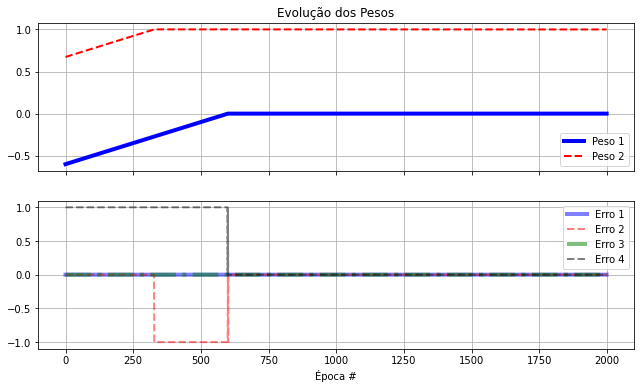

In [135]:
fig, ax = plt.subplots(nrows=2, ncols=1, sharex=True)
fig.set_dpi = 1200
fig.set_size_inches(16/1.5,9/1.5)

ax[0].plot(evolucaoPesos[:,0], ls='-', color='blue', lw=4, label='Peso 1')
ax[0].plot(evolucaoPesos[:,1], ls='--', color='red', lw=2, label='Peso 2')
ax[0].legend()
ax[0].grid()
ax[0].set_title('Evolução dos Pesos')

ax[1].plot(evolucaoErros[:,0], ls='-', color='blue', lw=4, label='Erro 1', alpha=0.5)
ax[1].plot(evolucaoErros[:,1], ls='--', color='red', lw=2, label='Erro 2', alpha=0.5)
ax[1].plot(evolucaoErros[:,2], ls='-.', color='green', lw=4, label='Erro 3', alpha=0.5)
ax[1].plot(evolucaoErros[:,3], ls='--', color='black', lw=2, label='Erro 4', alpha=0.5)
ax[1].legend()
ax[1].grid()
ax[1].set_xlabel('Época #')
fig.show()

In [126]:
pesos

array([0.00149494, 0.99918279])

In [127]:
ryan = Sinapse(entradas, pesos)
ryan2 = stepFunction(ryan)
ryan2

array([0., 0., 0., 1.])